<a href="https://colab.research.google.com/github/Prithivi-r/DS_day01_EcommercePrediction/blob/main/Ecommerce_Product_Return_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("ecommerce_product_returns_100.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (100, 9)


,Order_ID,Product_ID,Product_Category,Size,Price,Customer_History,Delivery_Time,Return_Status,Return_Reason
0,ORD001,P122,Dresses,S,2318,New,2,Not Returned,No Return
1,ORD002,P101,Accessories,S,804,New,1,Returned,Late Delivery
2,ORD003,P101,Accessories,M,933,Repeat,4,Returned,Late Delivery
3,ORD004,P104,T-Shirts,XL,748,New,2,Not Returned,No Return
4,ORD005,P115,Dresses,XL,998,New,3,Returned,Size Issue


In [2]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

Number of rows: 100
Number of columns: 9

Column names:
['Order_ID', 'Product_ID', 'Product_Category', 'Size', 'Price', 'Customer_History', 'Delivery_Time', 'Return_Status', 'Return_Reason']

Missing values:
Order_ID            0
Product_ID          0
Product_Category    0
Size                0
Price               0
Customer_History    0
Delivery_Time       0
Return_Status       0
Return_Reason       0
dtype: int64

Duplicate rows:
0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Order_ID          100 non-null    object
 1   Product_ID        100 non-null    object
 2   Product_Category  100 non-null    object
 3   Size              100 non-null    object
 4   Price             100 non-null    int64 
 5   Customer_History  100 non-null    object
 6   Delivery_Time     100 non-null    int64 
 7   Return_Status     100 non-null    object
 8   Return_Reason     100 non-null    object
dtypes: int64(2), object(7)
memory usage: 7.2+ KB


In [4]:
df.describe()

,Price,Delivery_Time
count,100.000000,100.00000
mean,1275.720000,3.95000
std,685.833403,2.09557
min,285.000000,1.00000
25%,770.500000,2.00000
50%,1128.500000,4.00000
75%,1671.250000,5.00000
max,3144.000000,8.00000


In [5]:
return_counts = df["Return_Status"].value_counts()

print(return_counts)

return_rate = (df["Return_Status"] == "Returned").mean() * 100

print("\nOverall Return Rate:", round(return_rate, 2), "%")

Return_Status
Not Returned    64
Returned        36
Name: count, dtype: int64

Overall Return Rate: 36.0 %


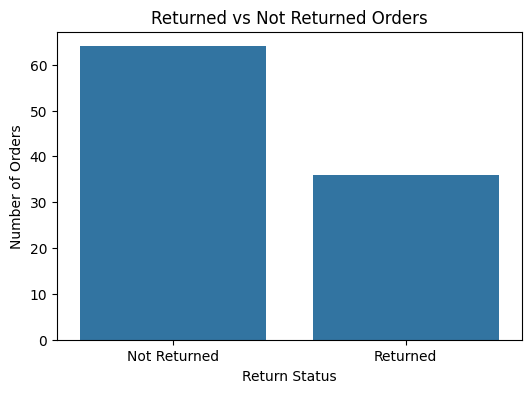

In [6]:
plt.figure(figsize=(6,4))

sns.countplot(data=df, x="Return_Status")

plt.title("Returned vs Not Returned Orders")
plt.xlabel("Return Status")
plt.ylabel("Number of Orders")

plt.show()

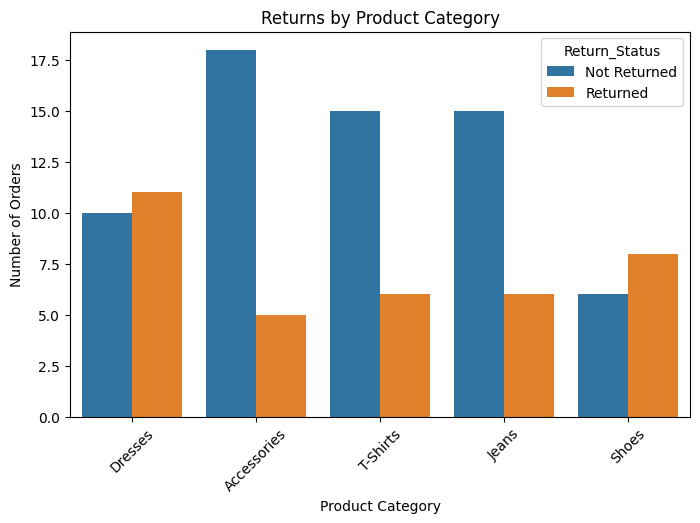

In [7]:
plt.figure(figsize=(8,5))

sns.countplot(data=df, x="Product_Category", hue="Return_Status")

plt.title("Returns by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Number of Orders")

plt.xticks(rotation=45)

plt.show()

In [8]:
category_return_rate = (
    df.groupby("Product_Category")["Return_Status"]
    .apply(lambda x: (x == "Returned").mean() * 100)
    .sort_values(ascending=False)
)

print(category_return_rate)

Product_Category
Shoes          57.142857
Dresses        52.380952
Jeans          28.571429
T-Shirts       28.571429
Accessories    21.739130
Name: Return_Status, dtype: float64


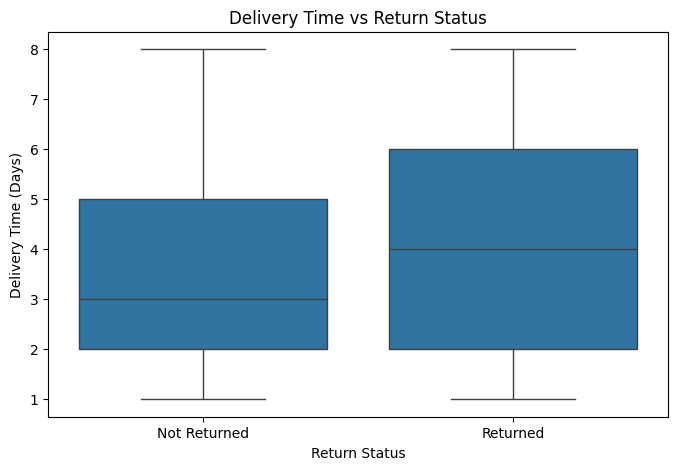

In [9]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="Return_Status",
    y="Delivery_Time"
)

plt.title("Delivery Time vs Return Status")
plt.xlabel("Return Status")
plt.ylabel("Delivery Time (Days)")

plt.show()

In [10]:
df["Delivery_Delay"] = np.where(
    df["Delivery_Time"] >= 5,
    "Delayed",
    "On Time"
)

print(
    pd.crosstab(
        df["Delivery_Delay"],
        df["Return_Status"],
        normalize="index"
    ) * 100
)

Return_Status   Not Returned   Returned
Delivery_Delay                         
Delayed            61.111111  38.888889
On Time            65.625000  34.375000


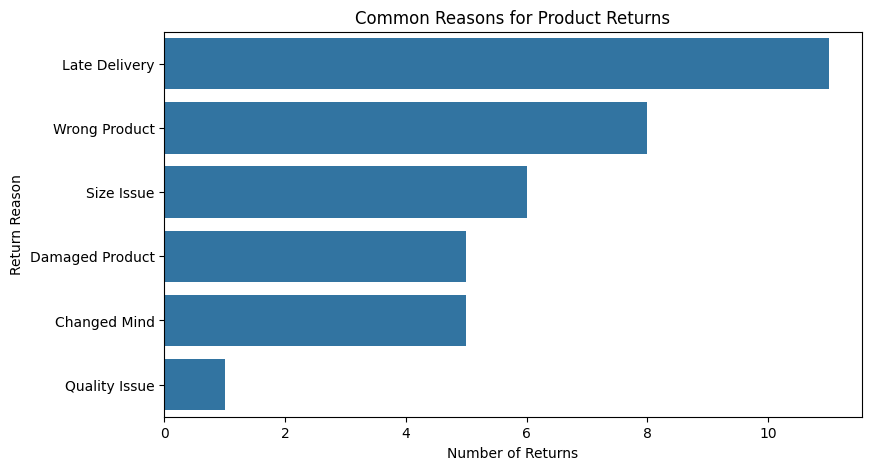

In [11]:
returned_df = df[df["Return_Status"] == "Returned"]

plt.figure(figsize=(9,5))

sns.countplot(
    data=returned_df,
    y="Return_Reason",
    order=returned_df["Return_Reason"].value_counts().index
)

plt.title("Common Reasons for Product Returns")
plt.xlabel("Number of Returns")
plt.ylabel("Return Reason")

plt.show()

In [12]:
customer_return_rate = (
    df.groupby("Customer_History")["Return_Status"]
    .apply(lambda x: (x == "Returned").mean() * 100)
)

print("Return Rate by Customer Type:")
print(customer_return_rate)

Return Rate by Customer Type:
Customer_History
New       22.5
Repeat    45.0
Name: Return_Status, dtype: float64


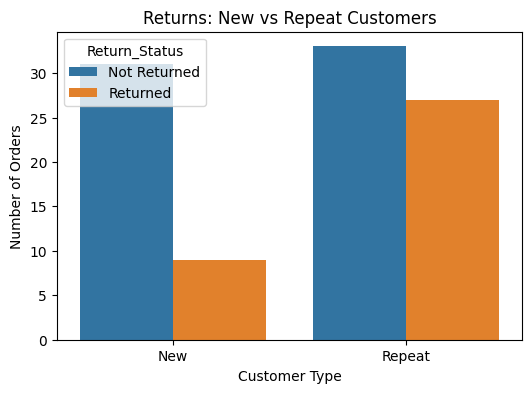

In [13]:
plt.figure(figsize=(6,4))

sns.countplot(
    data=df,
    x="Customer_History",
    hue="Return_Status"
)

plt.title("Returns: New vs Repeat Customers")
plt.xlabel("Customer Type")
plt.ylabel("Number of Orders")

plt.show()

In [14]:
product_returns = (
    df[df["Return_Status"] == "Returned"]
    .groupby("Product_ID")
    .size()
    .sort_values(ascending=False)
)

print("Products with highest number of returns:")
print(product_returns.head(10))

Products with highest number of returns:
Product_ID
P101    3
P102    3
P121    3
P109    2
P108    2
P125    2
P120    2
P115    2
P111    2
P119    2
dtype: int64


In [15]:
X = df.drop(
    ["Order_ID", "Product_ID", "Return_Status", "Return_Reason"],
    axis=1
)

y = df["Return_Status"]

In [16]:
X = pd.get_dummies(X, drop_first=True)

print(X.head())
print("\nFeatures:", X.columns.tolist())

   Price  Delivery_Time  Product_Category_Dresses  Product_Category_Jeans  \
0   2318              2                      True                   False   
1    804              1                     False                   False   
2    933              4                     False                   False   
3    748              2                     False                   False   
4    998              3                      True                   False   

   Product_Category_Shoes  Product_Category_T-Shirts  Size_M  Size_S  Size_XL  \
0                   False                      False   False    True    False   
1                   False                      False   False    True    False   
2                   False                      False    True   False    False   
3                   False                       True   False   False     True   
4                   False                      False   False   False     True   

   Customer_History_Repeat  Delivery_Delay_On Time

In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (80, 11)
Testing data: (20, 11)


In [18]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [19]:
y_pred = model.predict(X_test)

print("Predictions:")
print(y_pred)

Predictions:
['Not Returned' 'Not Returned' 'Returned' 'Returned' 'Not Returned'
 'Not Returned' 'Returned' 'Returned' 'Returned' 'Not Returned' 'Returned'
 'Not Returned' 'Not Returned' 'Returned' 'Returned' 'Not Returned'
 'Not Returned' 'Not Returned' 'Not Returned' 'Returned']


In [20]:
from sklearn.metrics import accuracy_score, classification_report

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 60.0 %

Classification Report:
              precision    recall  f1-score   support

Not Returned       0.73      0.62      0.67        13
    Returned       0.44      0.57      0.50         7

    accuracy                           0.60        20
   macro avg       0.59      0.59      0.58        20
weighted avg       0.63      0.60      0.61        20



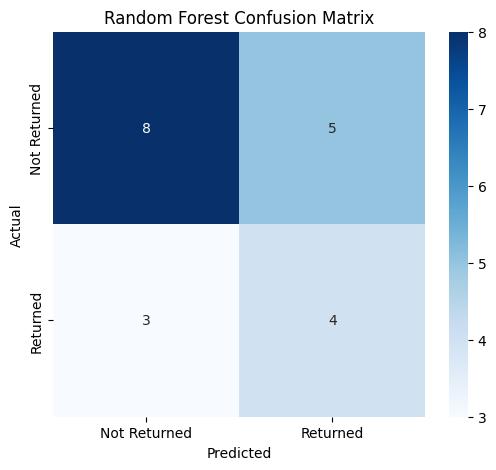

In [21]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Returned", "Returned"],
    yticklabels=["Not Returned", "Returned"]
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [22]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance)

                      Feature  Importance
0                       Price    0.350229
1               Delivery_Time    0.209098
9     Customer_History_Repeat    0.080564
6                      Size_M    0.052623
2    Product_Category_Dresses    0.050110
4      Product_Category_Shoes    0.050044
8                     Size_XL    0.048381
5   Product_Category_T-Shirts    0.045212
10     Delivery_Delay_On Time    0.039658
7                      Size_S    0.038754
3      Product_Category_Jeans    0.035328


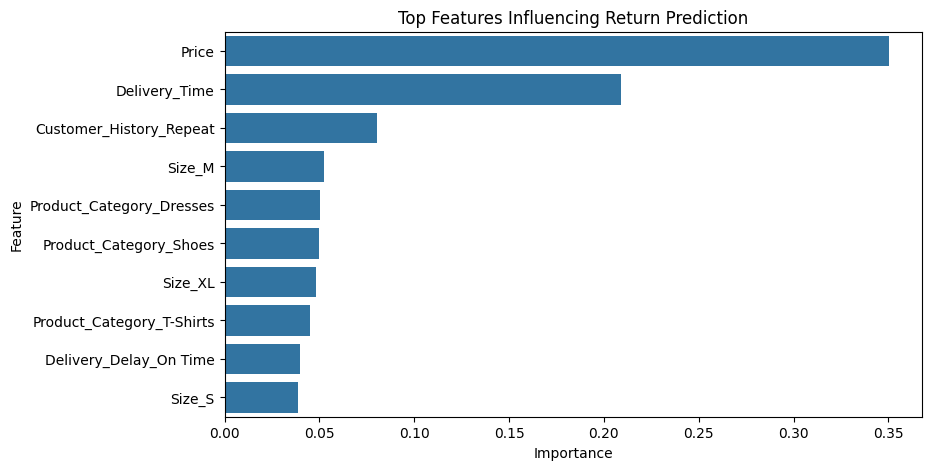

In [23]:
plt.figure(figsize=(9,5))

sns.barplot(
    data=importance.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top Features Influencing Return Prediction")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.show()